<a href="https://colab.research.google.com/github/junelwc6-source/IBM-HR-Attrition-Analytics/blob/main/IBM_HR_Attrition_Capstone.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Employee Attrition Analysis and Prediction

## 1. Data Understanding

#This project uses five IBM HR Analytics datasets to explore employee attrition patterns and develop a predictive model.

#The first step is to load the datasets and examine their structure and quality.

In [1]:

import pandas as pd

# Load the five IBM HR datasets
employees = pd.read_csv("Employees.csv")
compensation = pd.read_csv("Compensation.csv")
performance = pd.read_csv("Performance.csv")
experience = pd.read_csv("Experience.csv")
status = pd.read_csv("Employment Status.csv")

# Check the number of rows and columns
print("Employees:", employees.shape)
print("Compensation:", compensation.shape)
print("Performance:", performance.shape)
print("Experience:", experience.shape)
print("Employment Status:", status.shape)


Employees: (1470, 14)
Compensation: (1470, 7)
Performance: (1470, 7)
Experience: (1470, 8)
Employment Status: (1470, 3)


In [2]:

# Check data quality for all five datasets

datasets = {
    "Employees": employees,
    "Compensation": compensation,
    "Performance": performance,
    "Experience": experience,
    "Employment Status": status
}

for name, df in datasets.items():
    print("\n", name)
    print("Missing values:", df.isnull().sum().sum())
    print("Duplicate Employee IDs:", df["EmployeeNumber"].duplicated().sum())



 Employees
Missing values: 5
Duplicate Employee IDs: 0

 Compensation
Missing values: 0
Duplicate Employee IDs: 0

 Performance
Missing values: 0
Duplicate Employee IDs: 0

 Experience
Missing values: 0
Duplicate Employee IDs: 0

 Employment Status
Missing values: 0
Duplicate Employee IDs: 0


In [3]:

# Identify columns with missing values
print(employees.isnull().sum())

# Display records containing missing values
display(employees[employees.isnull().any(axis=1)])


EmployeeNumber      0
Age                 5
Gender              0
MaritalStatus       0
Education           0
EducationField      0
Department          0
JobRole             0
JobLevel            0
BusinessTravel      0
DistanceFromHome    0
EmployeeCount       0
Over18              0
StandardHours       0
dtype: int64


,EmployeeNumber,Age,Gender,MaritalStatus,Education,EducationField,Department,JobRole,JobLevel,BusinessTravel,DistanceFromHome,EmployeeCount,Over18,StandardHours
5,8,NaN,Male,Single,2,Life Sciences,Research & Development,Laboratory Technician,1,Travel_Frequently,2,1,Y,80
27,35,NaN,Male,Married,4,Marketing,Sales,Sales Executive,2,Travel_Rarely,8,1,Y,80
134,177,NaN,Female,Married,1,Life Sciences,Human Resources,Human Resources,1,Travel_Rarely,25,1,Y,80
262,362,NaN,Male,Single,1,Technical Degree,Research & Development,Laboratory Technician,2,Travel_Rarely,2,1,Y,80
377,501,NaN,Female,Married,3,Life Sciences,Research & Development,Research Scientist,1,Travel_Rarely,2,1,Y,80


In [4]:

# Check the median age before cleaning
print("Median Age:", employees["Age"].median())

# Replace missing ages with the median age
employees["Age"] = employees["Age"].fillna(
    employees["Age"].median()
)

# Verify that no missing values remain
print("Missing Age values after cleaning:",
      employees["Age"].isnull().sum())


Median Age: 36.0
Missing Age values after cleaning: 0


### Data Cleaning – Missing Values

The initial data quality check identified five missing values in the Age column of the Employees dataset, representing approximately 0.34% of the 1,470 employee records.

The missing values were replaced using the median age to retain all employee records and minimise the influence of extreme values.

No duplicate Employee IDs were identified across the five datasets.

In [5]:

# Check whether Employee IDs match across all datasets

employee_ids = set(employees["EmployeeNumber"])

for name, df in datasets.items():
    ids = set(df["EmployeeNumber"])

    print(name)
    print("IDs missing from this dataset:",
          len(employee_ids - ids))
    print("Extra IDs in this dataset:",
          len(ids - employee_ids))
    print()


Employees
IDs missing from this dataset: 0
Extra IDs in this dataset: 0

Compensation
IDs missing from this dataset: 0
Extra IDs in this dataset: 0

Performance
IDs missing from this dataset: 0
Extra IDs in this dataset: 0

Experience
IDs missing from this dataset: 0
Extra IDs in this dataset: 0

Employment Status
IDs missing from this dataset: 0
Extra IDs in this dataset: 0



In [6]:

# Merge the five IBM HR datasets into one master dataframe

df = employees.merge(compensation, on="EmployeeNumber", validate="one_to_one")

df = df.merge(performance, on="EmployeeNumber", validate="one_to_one")

df = df.merge(experience, on="EmployeeNumber", validate="one_to_one")

df = df.merge(status, on="EmployeeNumber", validate="one_to_one")

# Check the merged dataset
print("Merged dataset shape:", df.shape)
print("Duplicate Employee IDs:", df["EmployeeNumber"].duplicated().sum())
print("Total missing values:", df.isnull().sum().sum())

# Display the first 5 rows
display(df.head())


Merged dataset shape: (1470, 35)
Duplicate Employee IDs: 0
Total missing values: 0


,EmployeeNumber,Age,Gender,MaritalStatus,Education,EducationField,Department,JobRole,JobLevel,BusinessTravel,...,WorkLifeBalance,NumCompaniesWorked,TotalWorkingYears,TrainingTimesLastYear,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,Attrition,OverTime
0,1,41.0,Female,Single,2,Life Sciences,Sales,Sales Executive,2,Travel_Rarely,...,1,8,8,0,6,4,0,5,Yes,Yes
1,2,49.0,Male,Married,1,Life Sciences,Research & Development,Research Scientist,2,Travel_Frequently,...,3,1,10,3,10,7,1,7,No,No
2,4,37.0,Male,Single,2,Other,Research & Development,Laboratory Technician,1,Travel_Rarely,...,3,6,7,3,0,0,0,0,Yes,Yes
3,5,33.0,Female,Married,4,Life Sciences,Research & Development,Research Scientist,1,Travel_Frequently,...,3,1,8,3,8,7,3,0,No,Yes
4,7,27.0,Male,Married,1,Medical,Research & Development,Laboratory Technician,1,Travel_Rarely,...,3,9,6,3,2,2,2,2,No,No


### Data Integration

The five IBM HR Analytics datasets were merged using `EmployeeNumber` as the common identifier.

Prior to merging, data validation confirmed that all five datasets contained 1,470 unique Employee IDs, with no missing or additional IDs across the datasets.

A one-to-one merge was performed to combine employee demographics, compensation, performance, experience and employment status into a single dataset for subsequent analysis.

In [7]:

# Analyse overall employee attrition

print("Employee Attrition Count:")
print(df["Attrition"].value_counts())

print("\nEmployee Attrition Rate (%):")
print(df["Attrition"].value_counts(normalize=True) * 100)


Employee Attrition Count:
Attrition
No     1233
Yes     237
Name: count, dtype: int64

Employee Attrition Rate (%):
Attrition
No     83.877551
Yes    16.122449
Name: proportion, dtype: float64


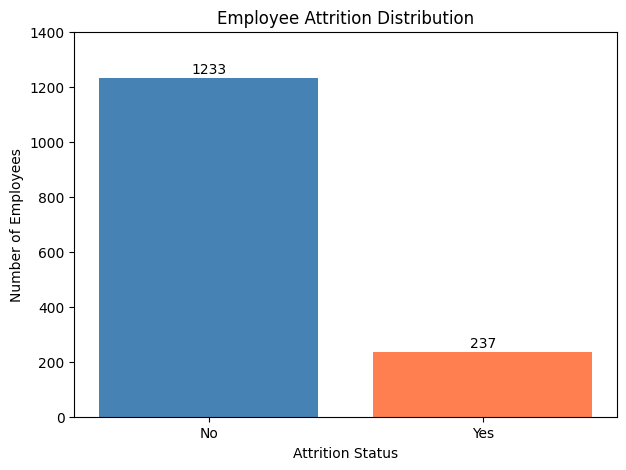

In [8]:

import matplotlib.pyplot as plt

# Count employees by attrition status
attrition_counts = df["Attrition"].value_counts()

# Create bar chart
plt.figure(figsize=(7, 5))

bars = plt.bar(
    attrition_counts.index,
    attrition_counts.values,
    color=["steelblue", "coral"]
)

# Add numbers above bars
for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 15,
        int(bar.get_height()),
        ha="center"
    )

plt.title("Employee Attrition Distribution")
plt.xlabel("Attrition Status")
plt.ylabel("Number of Employees")
plt.ylim(0, 1400)
plt.show()


### Finding 1: Overall Employee Attrition

The dataset contains 1,470 employees, of whom 237 (16.12%) are recorded as having left the organisation, while 1,233 (83.88%) remained.

This provides a baseline for analysing attrition patterns across different employee groups and identifying factors associated with employee turnover.

In [9]:

# Calculate attrition by department

department_attrition = (
    df.groupby("Department")["Attrition"]
    .agg(
        Total_Employees="count",
        Employees_Left=lambda x: (x == "Yes").sum()
    )
)

# Calculate attrition rate
department_attrition["Attrition_Rate"] = (
    department_attrition["Employees_Left"] /
    department_attrition["Total_Employees"] * 100
).round(2)

# Sort by highest attrition rate
department_attrition = department_attrition.sort_values(
    "Attrition_Rate", ascending=False
)

display(department_attrition)


,Total_Employees,Employees_Left,Attrition_Rate
Department,,,
Sales,446,92,20.63
Human Resources,63,12,19.05
Research & Development,961,133,13.84


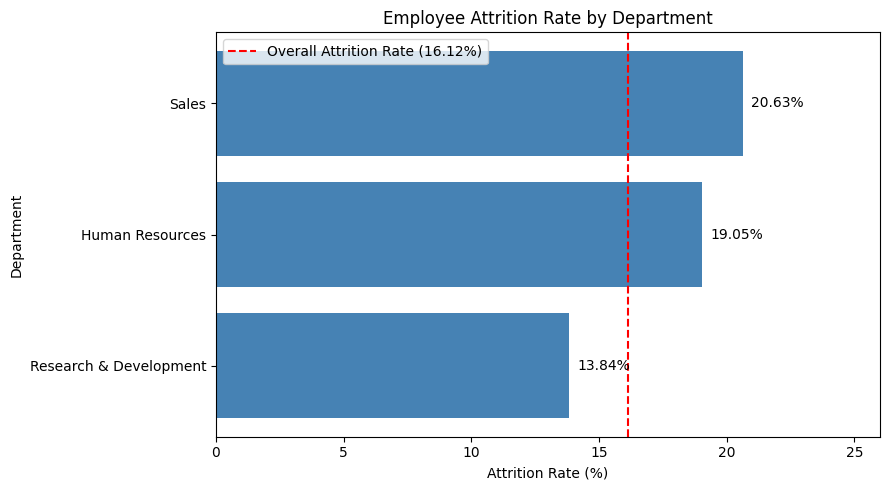

In [10]:

# Visualise attrition rate by department

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

bars = plt.barh(
    department_attrition.index,
    department_attrition["Attrition_Rate"],
    color="steelblue"
)

# Display highest attrition rate at the top
plt.gca().invert_yaxis()

# Add percentage labels
for bar in bars:
    plt.text(
        bar.get_width() + 0.3,
        bar.get_y() + bar.get_height() / 2,
        f"{bar.get_width():.2f}%",
        va="center"
    )

# Add overall attrition rate for comparison
plt.axvline(
    x=16.12,
    color="red",
    linestyle="--",
    label="Overall Attrition Rate (16.12%)"
)

plt.title("Employee Attrition Rate by Department")
plt.xlabel("Attrition Rate (%)")
plt.ylabel("Department")
plt.xlim(0, 26)
plt.legend()
plt.tight_layout()
plt.show()


### Finding 2: Employee Attrition by Department

Sales recorded the highest attrition rate at 20.63%, followed by Human Resources at 19.05%. Research & Development had the lowest attrition rate at 13.84%.

Sales and Human Resources exceeded the overall attrition rate of 16.12%, suggesting that these departments may warrant further investigation into factors associated with employee turnover.

The findings could help HR teams prioritise retention analysis and support workforce planning.

In [11]:

# Analyse employee attrition by job role

jobrole_attrition = (
    df.groupby("JobRole")["Attrition"]
    .agg(
        Total_Employees="count",
        Employees_Left=lambda x: (x == "Yes").sum()
    )
)

# Calculate attrition rate
jobrole_attrition["Attrition_Rate"] = (
    jobrole_attrition["Employees_Left"] /
    jobrole_attrition["Total_Employees"] * 100
).round(2)

# Sort from highest to lowest attrition rate
jobrole_attrition = jobrole_attrition.sort_values(
    "Attrition_Rate", ascending=False
)

display(jobrole_attrition)


,Total_Employees,Employees_Left,Attrition_Rate
JobRole,,,
Sales Representative,83,33,39.76
Laboratory Technician,259,62,23.94
Human Resources,52,12,23.08
Sales Executive,326,57,17.48
Research Scientist,292,47,16.10
Manufacturing Director,145,10,6.90
Healthcare Representative,131,9,6.87
Manager,102,5,4.90
Research Director,80,2,2.50


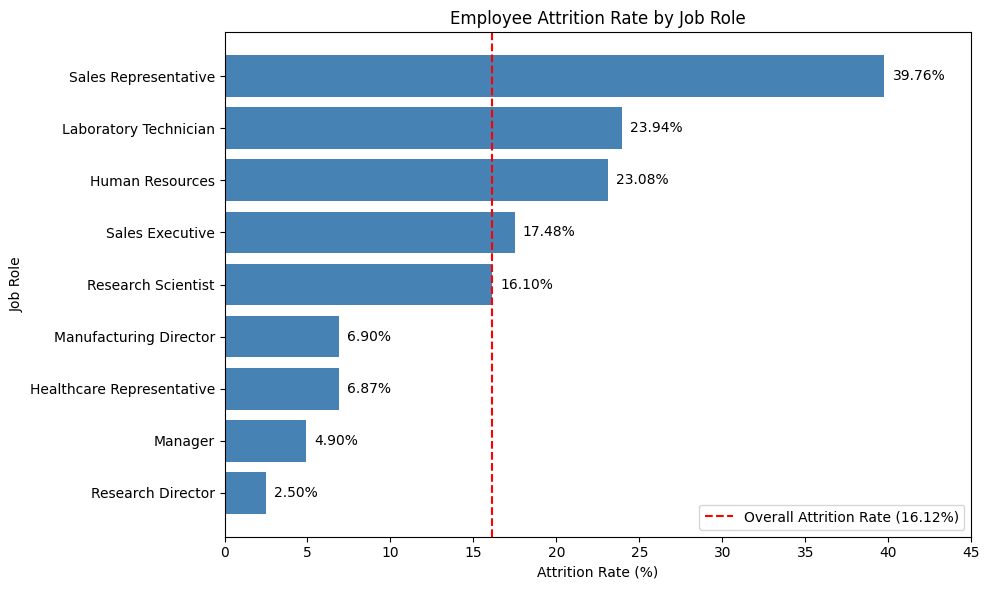

In [12]:

# Visualise employee attrition rate by job role

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

bars = plt.barh(
    jobrole_attrition.index,
    jobrole_attrition["Attrition_Rate"],
    color="steelblue"
)

# Highest attrition rate at the top
plt.gca().invert_yaxis()

# Add percentage labels
for bar in bars:
    plt.text(
        bar.get_width() + 0.5,
        bar.get_y() + bar.get_height() / 2,
        f"{bar.get_width():.2f}%",
        va="center"
    )

# Overall attrition rate
overall_rate = (df["Attrition"] == "Yes").mean() * 100

plt.axvline(
    overall_rate,
    color="red",
    linestyle="--",
    label=f"Overall Attrition Rate ({overall_rate:.2f}%)"
)

plt.title("Employee Attrition Rate by Job Role")
plt.xlabel("Attrition Rate (%)")
plt.ylabel("Job Role")
plt.xlim(0, 45)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


### Finding 3: Employee Attrition by Job Role

Sales Representatives recorded the highest attrition rate at 39.76%, followed by Laboratory Technicians (23.94%) and Human Resources employees (23.08%).

Although Sales Representatives had the highest attrition rate, Laboratory Technicians accounted for the largest number of departures (62 employees).

These findings suggest that Sales Representatives and Laboratory Technicians may be priority groups for further investigation. Understanding the factors associated with attrition in these roles could help HR develop more targeted employee retention strategies.

In [13]:

# Analyse the relationship between overtime and attrition

overtime_attrition = (
    df.groupby("OverTime")["Attrition"]
    .agg(
        Total_Employees="count",
        Employees_Left=lambda x: (x == "Yes").sum()
    )
)

# Calculate attrition rate
overtime_attrition["Attrition_Rate"] = (
    overtime_attrition["Employees_Left"] /
    overtime_attrition["Total_Employees"] * 100
).round(2)

display(overtime_attrition)


,Total_Employees,Employees_Left,Attrition_Rate
OverTime,,,
No,1054,110,10.44
Yes,416,127,30.53


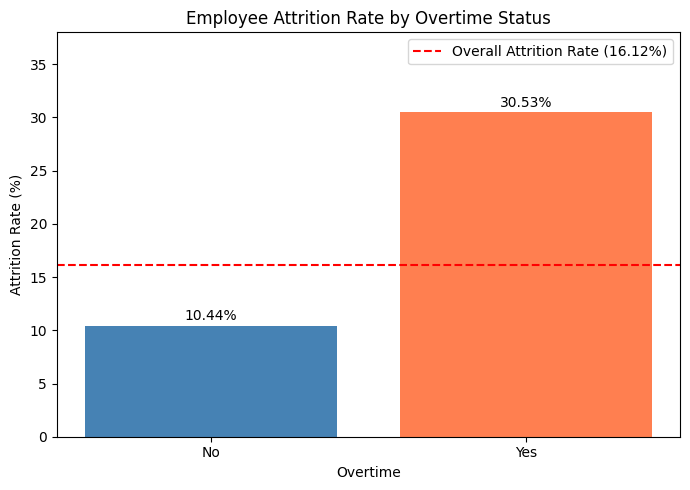

In [14]:

# Visualise attrition rate by overtime status

import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

bars = plt.bar(
    overtime_attrition.index,
    overtime_attrition["Attrition_Rate"],
    color=["steelblue", "coral"]
)

# Add percentage labels
for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{bar.get_height():.2f}%",
        ha="center"
    )

# Add overall attrition rate
overall_rate = (df["Attrition"] == "Yes").mean() * 100

plt.axhline(
    overall_rate,
    color="red",
    linestyle="--",
    label=f"Overall Attrition Rate ({overall_rate:.2f}%)"
)

plt.title("Employee Attrition Rate by Overtime Status")
plt.xlabel("Overtime")
plt.ylabel("Attrition Rate (%)")
plt.ylim(0, 38)
plt.legend()
plt.tight_layout()
plt.show()


### Finding 4: Relationship Between Overtime and Employee Attrition

Employees who worked overtime recorded an attrition rate of 30.53%, compared with 10.44% among employees who did not work overtime.

The attrition rate was approximately 2.9 times higher among employees working overtime, suggesting a strong association between overtime and employee turnover.

These findings indicate that workload management and overtime arrangements may warrant further investigation as part of employee retention strategies. However, the analysis does not establish a causal relationship.

In [15]:

# Analyse employee attrition by job satisfaction level

satisfaction_attrition = (
    df.groupby("JobSatisfaction")["Attrition"]
    .agg(
        Total_Employees="count",
        Employees_Left=lambda x: (x == "Yes").sum()
    )
)

# Calculate attrition rate
satisfaction_attrition["Attrition_Rate"] = (
    satisfaction_attrition["Employees_Left"] /
    satisfaction_attrition["Total_Employees"] * 100
).round(2)

display(satisfaction_attrition)


,Total_Employees,Employees_Left,Attrition_Rate
JobSatisfaction,,,
1,289,66,22.84
2,280,46,16.43
3,442,73,16.52
4,459,52,11.33


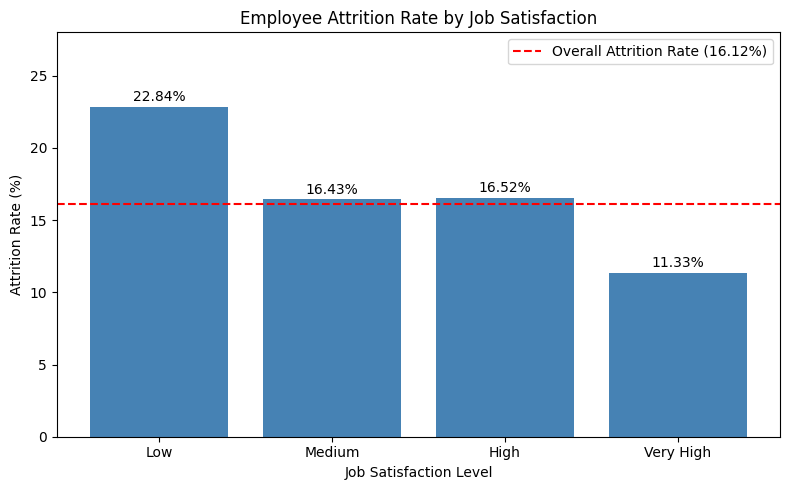

In [16]:

# Visualise attrition rate by job satisfaction

import matplotlib.pyplot as plt

satisfaction_labels = [
    "Low", "Medium", "High", "Very High"
]

plt.figure(figsize=(8, 5))

bars = plt.bar(
    satisfaction_labels,
    satisfaction_attrition["Attrition_Rate"],
    color="steelblue"
)

# Add percentage labels
for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.4,
        f"{bar.get_height():.2f}%",
        ha="center"
    )

# Add overall attrition rate
overall_rate = (df["Attrition"] == "Yes").mean() * 100

plt.axhline(
    overall_rate,
    color="red",
    linestyle="--",
    label=f"Overall Attrition Rate ({overall_rate:.2f}%)"
)

plt.title("Employee Attrition Rate by Job Satisfaction")
plt.xlabel("Job Satisfaction Level")
plt.ylabel("Attrition Rate (%)")
plt.ylim(0, 28)
plt.legend()
plt.tight_layout()
plt.show()


### Finding 5: Job Satisfaction and Employee Attrition

Employees with low job satisfaction recorded the highest attrition rate at 22.84%, compared with 11.33% among employees with very high job satisfaction.

This suggests that job satisfaction is associated with employee attrition and may be an important consideration when developing retention strategies.

Further analysis is needed to understand how job satisfaction interacts with other factors, such as overtime, compensation and career progression.

In [17]:

# Analyse employee attrition by work-life balance

worklife_attrition = (
    df.groupby("WorkLifeBalance")["Attrition"]
    .agg(
        Total_Employees="count",
        Employees_Left=lambda x: (x == "Yes").sum()
    )
)

# Calculate attrition rate
worklife_attrition["Attrition_Rate"] = (
    worklife_attrition["Employees_Left"] /
    worklife_attrition["Total_Employees"] * 100
).round(2)

display(worklife_attrition)


,Total_Employees,Employees_Left,Attrition_Rate
WorkLifeBalance,,,
1,80,25,31.25
2,344,58,16.86
3,893,127,14.22
4,153,27,17.65


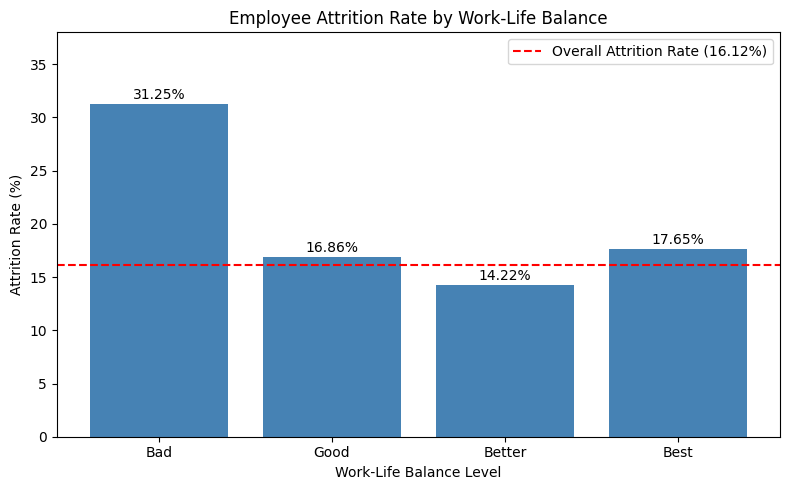

In [18]:

# Visualise attrition rate by work-life balance

import matplotlib.pyplot as plt

worklife_labels = ["Bad", "Good", "Better", "Best"]

plt.figure(figsize=(8, 5))

bars = plt.bar(
    worklife_labels,
    worklife_attrition["Attrition_Rate"],
    color="steelblue"
)

# Add percentage labels
for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{bar.get_height():.2f}%",
        ha="center"
    )

# Add overall attrition rate
overall_rate = (df["Attrition"] == "Yes").mean() * 100

plt.axhline(
    overall_rate,
    color="red",
    linestyle="--",
    label=f"Overall Attrition Rate ({overall_rate:.2f}%)"
)

plt.title("Employee Attrition Rate by Work-Life Balance")
plt.xlabel("Work-Life Balance Level")
plt.ylabel("Attrition Rate (%)")
plt.ylim(0, 38)
plt.legend()
plt.tight_layout()
plt.show()


### Finding 6: Work-Life Balance and Employee Attrition

Employees reporting poor work-life balance recorded the highest attrition rate at 31.25%, compared with 14.22% among employees reporting better work-life balance.

This suggests that work-life balance may be an important factor associated with employee attrition. However, the relationship is not consistent across all four levels, and further analysis is needed.

The findings indicate that workload management and employee well-being may be areas for HR to investigate when developing targeted retention strategies.